# portfolio-risk demo
Allocate with and without return forecasts, see the clusters HRP finds, and measure 1-day VaR/CVaR. Data: synthetic stocks plus 3 cointegrated pairs and a GARCH index.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from quantskills.data import synthetic_prices, to_wide
from quantskills.features import simple_returns
from quantskills.portfolio import (
    ALLOCATORS,
    allocate,
    cluster_order,
    cov_to_corr,
    ledoit_wolf_cov,
    pca_factors,
    risk_contributions,
    risk_report,
)

prices = synthetic_prices(seed=0, n_pairs=3, garch_index=True)
r = simple_returns(to_wide(prices)).iloc[-252:]
weights = pd.DataFrame({m: allocate(r, m) for m in ALLOCATORS})
weights.loc[weights["hrp"].sort_values(ascending=False).index[:8]].round(3)

,equal,inverse_vol,min_var,hrp,eigen
ticker,,,,,
IDX,0.027,0.042,0.328,0.120,0.002
SYN04,0.027,0.030,0.076,0.056,0.021
SYN17,0.027,0.029,0.079,0.055,0.023
SYN18,0.027,0.028,0.059,0.054,0.020
SYN21,0.027,0.030,0.073,0.044,0.023
PAIR2B,0.027,0.034,0.139,0.043,0.025
SYN07,0.027,0.029,0.052,0.039,0.023
SYN05,0.027,0.028,0.016,0.038,0.024


## Risk of each allocation (1-day, positive = loss)
In-sample: the weights were chosen on this same window.

In [2]:
pd.DataFrame({m: risk_report(r, weights[m]) for m in ALLOCATORS}).T[
    ["ann_vol", "var_hist_95", "cvar_hist_95", "var_hist_99", "cvar_hist_99", "var_cf_99"]
].round(4)

,ann_vol,var_hist_95,cvar_hist_95,var_hist_99,cvar_hist_99,var_cf_99
equal,0.1596,0.0148,0.0198,0.0229,0.0290,0.0236
inverse_vol,0.1539,0.0147,0.0191,0.0219,0.0279,0.0227
min_var,0.1008,0.0102,0.0122,0.0138,0.0140,0.0138
hrp,0.1300,0.0123,0.0161,0.0188,0.0231,0.0188
eigen,0.1672,0.0153,0.0209,0.0239,0.0302,0.0249


## What HRP sees: the clustered correlation matrix
The planted pairs (`PAIRkA` / `PAIRkB`) sit next to each other after clustering.

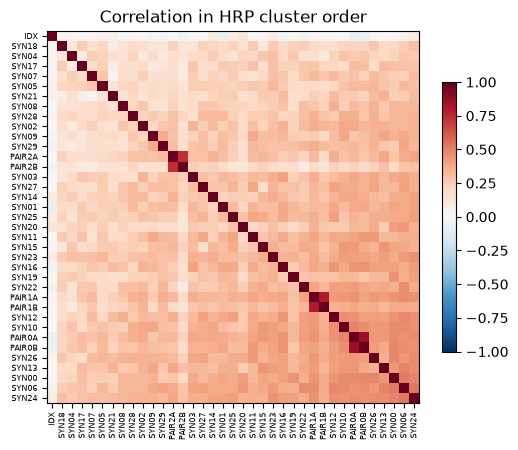

In [3]:
corr = cov_to_corr(ledoit_wolf_cov(r))
order = cluster_order(corr)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr.loc[order, order], cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order)), order, rotation=90, fontsize=6)
ax.set_yticks(range(len(order)), order, fontsize=6)
fig.colorbar(im, shrink=0.7)
ax.set_title("Correlation in HRP cluster order");

## PCA: one factor dominates (as simulated)

In [4]:
pca = pca_factors(r)
print("variance explained by PC1-PC5:", pca.explained.head(5).round(3).to_dict())
rc = risk_contributions(weights["hrp"], ledoit_wolf_cov(r))
print("largest HRP risk contributions:", rc.sort_values(ascending=False).head(3).round(3).to_dict())

variance explained by PC1-PC5: {'PC1': 0.327, 'PC2': 0.043, 'PC3': 0.037, 'PC4': 0.033, 'PC5': 0.032}
largest HRP risk contributions: {'SYN17': 0.05, 'SYN18': 0.049, 'SYN04': 0.048}


Strategy #7 (`unsupervised-risk`) rebalances these allocators on a rolling window; the terminal's `RISK` screen shows the same snapshot.